# CyberShield AI - Exploratory Data Analysis (EDA)
This notebook performs exploratory data analysis on the two core datasets used in CyberShield AI:
1. **PhiUSIIL Phishing URL Dataset**: Used to detect malicious URLs based on lexical, host, and webpage content features.
2. **Email Spam Dataset**: Used to detect spam/phishing email content.

In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

## 1. PhiUSIIL Phishing URL Dataset Analysis

In [2]:
url_path = '../datasets/PhiUSIIL/PhiUSIIL_Phishing_URL_Dataset.csv'
df_url = pd.read_csv(url_path)
print(f"PhiUSIIL URL Dataset Shape: {df_url.shape}")

PhiUSIIL URL Dataset Shape: (235795, 55)


In [3]:
df_url.head()

,URL,URLLength,Domain,DomainLength,IsDomainIP,TLD,URLSimilarityIndex,CharContinuationRate,TLDLegitimateProb,URLCharProb,...,Pay,Crypto,HasCopyrightInfo,NoOfImage,NoOfCSS,NoOfJS,NoOfSelfRef,NoOfEmptyRef,NoOfExternalRef,label
0,https://www.southbankmosaics.com,31,www.southbankmosaics.com,24,0,com,100.0,1.000000,0.522907,0.061933,...,0,0,1,34,20,28,119,0,124,1
1,https://www.uni-mainz.de,23,www.uni-mainz.de,16,0,de,100.0,0.666667,0.032650,0.050207,...,0,0,1,50,9,8,39,0,217,1
2,https://www.voicefmradio.co.uk,29,www.voicefmradio.co.uk,22,0,uk,100.0,0.866667,0.028555,0.064129,...,0,0,1,10,2,7,42,2,5,1
3,https://www.sfnmjournal.com,26,www.sfnmjournal.com,19,0,com,100.0,1.000000,0.522907,0.057606,...,1,1,1,3,27,15,22,1,31,1
4,https://www.rewildingargentina.org,33,www.rewildingargentina.org,26,0,org,100.0,1.000000,0.079963,0.059441,...,1,0,1,244,15,34,72,1,85,1


Class Counts:
 label
1    134850
0    100945
Name: count, dtype: int64

Class Percentages:
 label
1    57.189508
0    42.810492
Name: proportion, dtype: float64


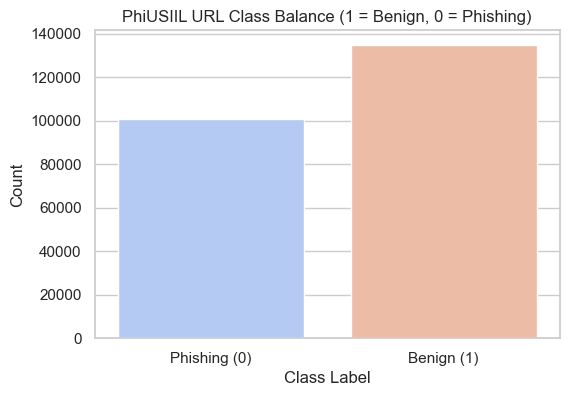

In [4]:
# Class Balance: 1 = Legitimate, 0 = Phishing
class_counts = df_url['label'].value_counts()
class_percentages = df_url['label'].value_counts(normalize=True) * 100

print("Class Counts:\n", class_counts)
print("\nClass Percentages:\n", class_percentages)

plt.figure(figsize=(6, 4))
sns.barplot(x=class_counts.index, y=class_counts.values, hue=class_counts.index, palette="coolwarm", legend=False)
plt.title("PhiUSIIL URL Class Balance (1 = Benign, 0 = Phishing)")
plt.xlabel("Class Label")
plt.ylabel("Count")
plt.xticks([0, 1], ['Phishing (0)', 'Benign (1)'])
plt.show()

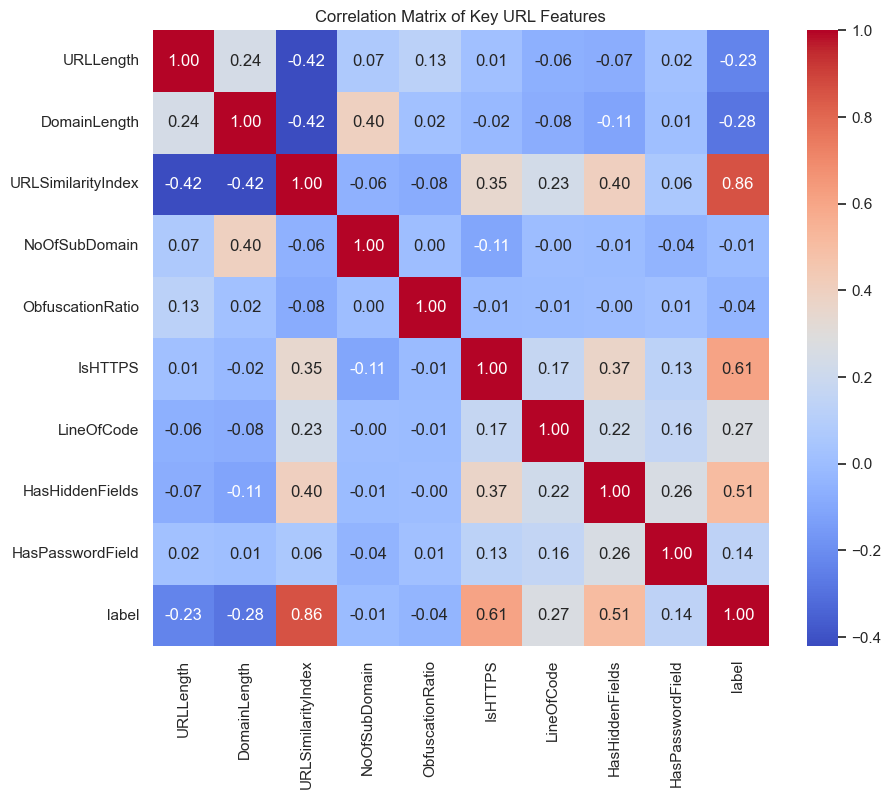

In [5]:
# Correlation of key numerical features with label
key_features = [
    'URLLength', 'DomainLength', 'URLSimilarityIndex', 'NoOfSubDomain',
    'ObfuscationRatio', 'IsHTTPS', 'LineOfCode', 'HasHiddenFields',
    'HasPasswordField', 'label'
]
corr_matrix = df_url[key_features].corr()

plt.figure(figsize=(10, 8))
sns.heatmap(corr_matrix, annot=True, cmap="coolwarm", fmt=".2f", square=True)
plt.title("Correlation Matrix of Key URL Features")
plt.show()

## 2. Email Spam Dataset Analysis

In [6]:
email_path = '../datasets/spamassassin/email_spam_dataset.csv'
df_email = pd.read_csv(email_path)
print(f"Email Dataset Shape: {df_email.shape}")

Email Dataset Shape: (5572, 2)


In [7]:
df_email.head()

,label,text
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."


Email Counts:
 label
ham     4825
spam     747
Name: count, dtype: int64

Email Percentages:
 label
ham     86.593683
spam    13.406317
Name: proportion, dtype: float64


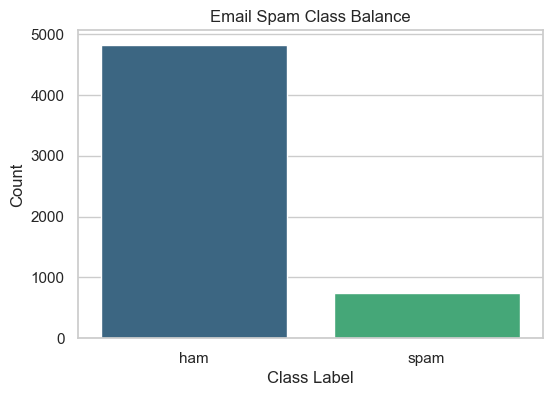

In [8]:
# Class Balance: ham vs spam
email_counts = df_email['label'].value_counts()
email_percentages = df_email['label'].value_counts(normalize=True) * 100

print("Email Counts:\n", email_counts)
print("\nEmail Percentages:\n", email_percentages)

plt.figure(figsize=(6, 4))
sns.barplot(x=email_counts.index, y=email_counts.values, hue=email_counts.index, palette="viridis", legend=False)
plt.title("Email Spam Class Balance")
plt.xlabel("Class Label")
plt.ylabel("Count")
plt.show()

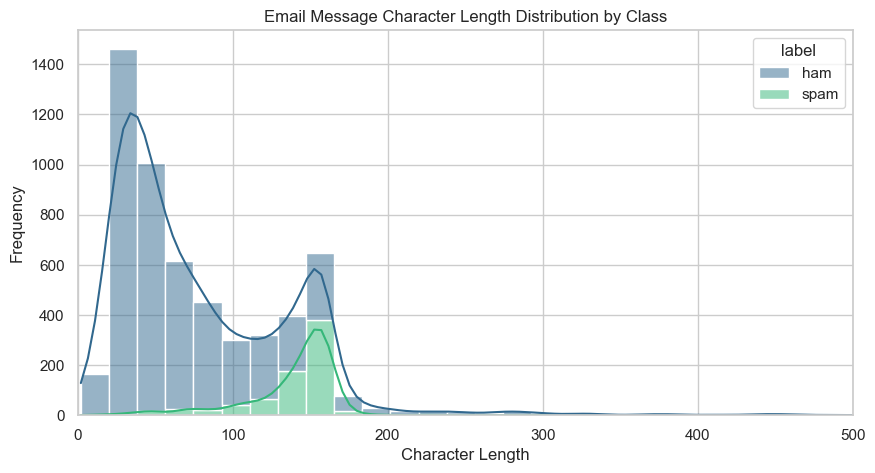

In [9]:
# Text Length Distribution Analysis
df_email['length'] = df_email['text'].astype(str).apply(len)

plt.figure(figsize=(10, 5))
sns.histplot(data=df_email, x="length", hue="label", kde=True, bins=50, palette="viridis", multiple="stack")
plt.title("Email Message Character Length Distribution by Class")
plt.xlabel("Character Length")
plt.ylabel("Frequency")
plt.xlim(0, 500) # limiting to typical short messages for visualization
plt.show()